# Flower Classification with a CNN - v1 (initial attempt)

First attempt at classifying 5 flower types (roses, daisy, dandelion, sunflowers, tulips).

> **Status:** this early draft contains small bugs that raise errors (see the `NOTE` comments in the cells).
> The corrected, improved version is `06_flower_cnn_v2_augmentation_dropout.ipynb`.
> It is kept here to show the learning progression.

In [1]:
# Imports: os/PIL for files and images, TensorFlow for the model.
# import cv2
import os
import PIL
import tensorflow as tf
import matplotlib.pyplot as plt


In [2]:
# Keras building blocks.
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [3]:
# Download the flower_photos dataset (about 3,670 images in 5 classes). cache_dir='.' stores it next to the notebook.
dataset_url="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir= tf.keras.utils.get_file('flower_photos',origin= dataset_url, cache_dir='.', untar=True)

In [4]:
# Path to the extracted dataset folder.
data_dir

'.\\datasets\\flower_photos'

In [5]:
# Convert the path to a pathlib.Path so we can use glob().
import pathlib
data_dir=pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos')

In [6]:
# List the first 5 image files.
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('datasets/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172636503_21bededa75_n.jpg')]

In [7]:
# Count all .jpg images in the dataset.
image_count=len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


In [8]:
# All rose images.
roses=list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('datasets/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

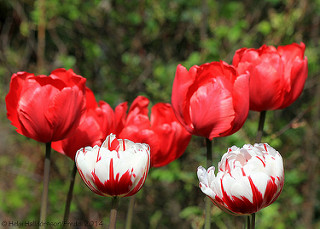

In [9]:
# Display one rose image.
PIL.Image.open(str(roses[50]))